# XGBoost — FAO land suitability
**Virginia tobacco, Regions I & II**

Third model, after the ordinal logistic baseline and the random forest. Same seed, same
stratified-block holdout, same ten rule predictors as the final forest, so all three are
evaluated on identical held-out blocks.

Everything here is tagged `xgb_` and written to `xgb_outputs/`, so nothing collides with
the LR or RF results.

**Why boosting needs more overfitting care than a forest.** A random forest averages
independent trees, so adding trees cannot overfit — only leaf size and feature sampling
can. Boosting fits each tree to the *residuals* of the previous ones, so the number of
rounds is itself a capacity parameter: run too long and it memorises. That is what
Stage 3's training curve measures, and why early stopping is set on a **spatially
blocked** inner split rather than a random one.

| Stage | What it does |
|---|---|
| 0–2 | Load, same holdout, features, class weights |
| 3 | Early stopping + the train/validation curve |
| 4 | Hyperparameter search on blocked CV |
| 5 | Final fit |
| 6–7 | Holdout metrics, confusion, blocked CV |
| 8 | Overfitting battery: random vs blocked, depth sweep, learning curve, shuffled labels |
| 9 | Rule vs non-rule ablation |
| 10–11 | Permutation importance, ALE |
| 12 | Three-model comparison |

## Setup

In [3]:
# !pip install xgboost scikit-learn pyarrow matplotlib joblib -q
import os, time, warnings, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import xgboost as xgb
import joblib
from sklearn.metrics import (f1_score, cohen_kappa_score, confusion_matrix,
                             accuracy_score, classification_report)
from sklearn.model_selection import StratifiedGroupKFold, StratifiedKFold
from sklearn.inspection import permutation_importance
from sklearn.utils.class_weight import compute_sample_weight

warnings.filterwarnings("ignore")
pd.set_option("display.width", 200, "display.max_columns", 60)
print("xgboost", xgb.__version__)

DATA_PATH = r"D:\Projects\capstone\feature_matrix.parquet"
OUT_DIR   = r"D:\Projects\capstone\xgb_outputs"
os.makedirs(OUT_DIR, exist_ok=True)
p_out = lambda n: os.path.join(OUT_DIR, n)

TARGET, BLOCK, REGION = "fao_class", "spatial_block", "region"
ORDER = ["N", "S3", "S2", "S1"]      # 0 = N .. 3 = S1
SEED  = 42                           # same holdout as LR and RF

MAX_ROUNDS  = 8000
EARLY_STOP  = 100
LR_RATE     = 0.05
PERM_SAMPLE = 40_000

code_of = {c: i for i, c in enumerate(ORDER)}
T0 = time.time()
tick = lambda m: print(f"[{(time.time()-T0)/60:6.1f} min] {m}", flush=True)
print("ready")

xgboost 3.2.0
ready


## Stage 0 — Load and reproduce the same spatial holdout

Identical seed and rule as the other two notebooks. **The class counts must match what
the LR and RF notebooks printed** — train 303,096 / holdout 72,026 over 105 blocks.

In [4]:
tick("loading")
df = pd.read_parquet(DATA_PATH).dropna(subset=[TARGET]).reset_index(drop=True)

rng = np.random.default_rng(SEED)
test_blocks = []
for _, g in df.groupby(REGION):
    has_rare = g.groupby(BLOCK)[TARGET].apply(lambda s: (s == ORDER[-1]).any())
    for flag in (True, False):
        b = has_rare[has_rare == flag].index.to_numpy()
        if len(b):
            test_blocks += list(rng.choice(b, size=max(1, int(0.2*len(b))), replace=False))

is_test = df[BLOCK].isin(test_blocks)
train = df[~is_test].reset_index(drop=True)
test  = df[is_test].reset_index(drop=True)

print(f"train {len(train):,} | holdout {len(test):,} over {len(test_blocks)} blocks")
pd.DataFrame({"train": train[TARGET].value_counts().reindex(ORDER),
              "holdout": test[TARGET].value_counts().reindex(ORDER)})

[   0.0 min] loading
train 303,096 | holdout 72,026 over 105 blocks


,train,holdout
fao_class,,
N,96141,23859
S3,95705,24295
S2,98014,21986
S1,13236,1886


## Stage 1 — Features, integer labels, class weights

The same ten Table 3.1 predictors the forest settled on. No transforms — boosted trees
are monotone-invariant like any tree ensemble.

Labels are encoded **0 = N … 3 = S1**, which means XGBoost's `predict_proba` columns are
already in suitability order. (The forest's were alphabetical and had to be reordered —
a silent-failure trap that does not arise here.)

Class imbalance is handled with per-sample weights rather than `scale_pos_weight`, which
is binary-only.

In [5]:
RULE = ["soil_ph", "slope_pct", "temp_gs_mean", "soc", "cec", "sand_pct",
        "clay_pct", "ndmi_median", "twi", "sunshine_rad"]

DROP = {TARGET, "fao_class_maxlim", "fao_class_storie", "index_sqrt",
        "index_storie", "limiting_factor", "region", "province", "row", "col",
        "x", "y", BLOCK, "sample_weight", "aspect"}
ALL_FEATURES = [c for c in df.columns if c not in DROP and df[c].dtype.kind in "fiu"]

FEATURES = [c for c in RULE if c in ALL_FEATURES]
assert len(FEATURES) == 10, FEATURES

X_tr, X_te = train[FEATURES], test[FEATURES]
y_tr = train[TARGET].map(code_of).to_numpy()
y_te = test[TARGET].map(code_of).to_numpy()
w_tr = compute_sample_weight("balanced", y_tr)

print(f"{len(FEATURES)} features:", FEATURES)
print(f"NaNs — train {int(X_tr.isna().sum().sum())}, holdout {int(X_te.isna().sum().sum())}")
pd.DataFrame({"class": ORDER,
              "train_n": np.bincount(y_tr, minlength=4),
              "weight": [round(float(w_tr[y_tr == i][0]), 3) for i in range(4)]})

10 features: ['soil_ph', 'slope_pct', 'temp_gs_mean', 'soc', 'cec', 'sand_pct', 'clay_pct', 'ndmi_median', 'twi', 'sunshine_rad']
NaNs — train 0, holdout 0


,class,train_n,weight
0,N,96141,0.788
1,S3,95705,0.792
2,S2,98014,0.773
3,S1,13236,5.725


## Helpers

In [6]:
BASE = dict(objective="multi:softprob", num_class=len(ORDER),
            eval_metric="mlogloss", tree_method="hist",
            learning_rate=LR_RATE, max_depth=6, min_child_weight=10,   # <- tuned
            subsample=0.8, colsample_bytree=0.8, reg_lambda=1.0,
            n_jobs=-1, random_state=SEED)

def make(**over):
    p = {**BASE, **over}
    return xgb.XGBClassifier(**p)

def fit_es(model, Xa, ya, wa, Xb, yb, rounds=EARLY_STOP):
    """Fit with early stopping, tolerating the xgboost 1.x / 2.x API split."""
    try:                                  # xgboost >= 2.0
        model.set_params(early_stopping_rounds=rounds)
        model.fit(Xa, ya, sample_weight=wa, eval_set=[(Xa, ya), (Xb, yb)],
                  verbose=False)
    except TypeError:                     # xgboost 1.x
        model.fit(Xa, ya, sample_weight=wa, eval_set=[(Xa, ya), (Xb, yb)],
                  early_stopping_rounds=rounds, verbose=False)
    return model

def best_rounds(model):
    for attr in ("best_iteration", "best_ntree_limit"):
        v = getattr(model, attr, None)
        if v:
            return int(v)
    return model.n_estimators

def mf1(t, p):
    return f1_score(t, p, average="macro")

def blocked_split(X, y, groups, n=5):
    return StratifiedGroupKFold(n_splits=n, shuffle=True,
                                random_state=SEED).split(X, y, groups)
print("ok")

ok


## Stage 2 — Blocked inner split for early stopping

Early stopping needs a validation set, and **it must respect blocks**. A random
validation split would contain cells adjacent to training cells, so validation loss would
keep falling long after the model stopped generalising, and boosting would run far past
the right number of rounds.

20% of training blocks are held out for this purpose. They are *inside* the training set —
the real holdout is never touched.

In [7]:
blocks_tr = train[BLOCK].to_numpy()
ub = np.unique(blocks_tr)
val_b = rng.choice(ub, size=max(1, int(0.2 * len(ub))), replace=False)
is_val = np.isin(blocks_tr, val_b)

Xa, ya, wa = X_tr[~is_val], y_tr[~is_val], w_tr[~is_val]
Xb, yb     = X_tr[is_val],  y_tr[is_val]
print(f"inner train {len(Xa):,} ({len(ub)-len(val_b)} blocks) | "
      f"inner valid {len(Xb):,} ({len(val_b)} blocks)")
print("inner valid classes:", dict(zip(ORDER, np.bincount(yb, minlength=4))))

inner train 249,841 (342 blocks) | inner valid 53,255 (85 blocks)
inner valid classes: {'N': np.int64(18200), 'S3': np.int64(15709), 'S2': np.int64(16036), 'S1': np.int64(3310)}


## Stage 3 — Early stopping and the training curve

**The single most informative overfitting diagnostic for boosting.** Training loss falls
monotonically by construction; the validation curve is what matters. If it bottoms out
and then rises, the rounds after the minimum are memorisation, and early stopping cuts
them off. A validation curve that is still falling at `MAX_ROUNDS` means the model is
under-trained, not over-trained.

[   0.0 min] early-stopped fit
[   2.1 min] stopped at round 3091 of 8000


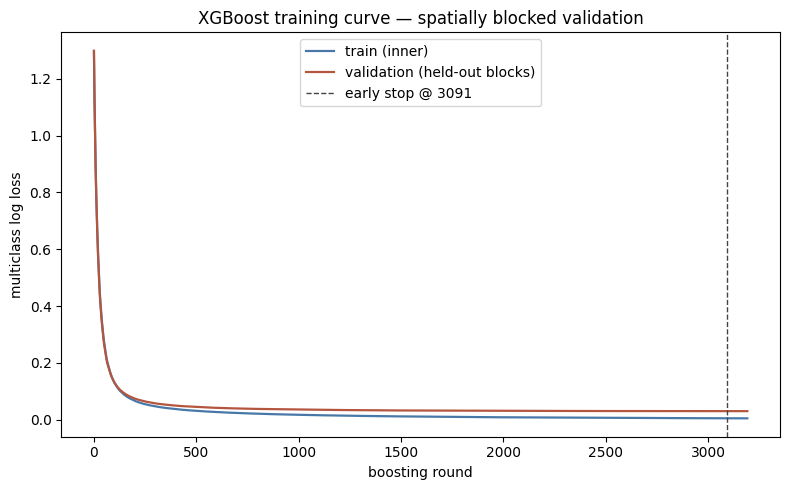

min validation mlogloss 0.03036 at round 3091
gap at stop: train 0.00529 vs valid 0.03036


In [8]:
tick("early-stopped fit")
m0 = fit_es(make(n_estimators=MAX_ROUNDS), Xa, ya, wa, Xb, yb)
BEST_ROUNDS = best_rounds(m0)
hist = m0.evals_result()
tr_curve = hist["validation_0"]["mlogloss"]
va_curve = hist["validation_1"]["mlogloss"]
tick(f"stopped at round {BEST_ROUNDS} of {MAX_ROUNDS}")

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(tr_curve, label="train (inner)", lw=1.6, color="#4878A8")
ax.plot(va_curve, label="validation (held-out blocks)", lw=1.6, color="#B4553F")
ax.axvline(BEST_ROUNDS, color="#444", ls="--", lw=1,
           label=f"early stop @ {BEST_ROUNDS}")
ax.set_xlabel("boosting round"); ax.set_ylabel("multiclass log loss")
ax.set_title("XGBoost training curve — spatially blocked validation")
ax.legend(); fig.tight_layout()
fig.savefig(p_out("xgb_training_curve.png"), dpi=170); plt.show()

pd.DataFrame({"round": range(len(tr_curve)), "train_mlogloss": tr_curve,
              "valid_mlogloss": va_curve}).to_csv(
    p_out("xgb_training_curve.csv"), index=False)
print(f"min validation mlogloss {min(va_curve):.5f} at round {int(np.argmin(va_curve))}")
print(f"gap at stop: train {tr_curve[BEST_ROUNDS-1]:.5f} "
      f"vs valid {va_curve[BEST_ROUNDS-1]:.5f}")

## Stage 4 — Hyperparameter search on blocked CV

Selected on blocked cross-validation, never on the holdout, so the holdout estimate stays
unbiased. `max_depth` and `min_child_weight` are the two that control capacity most
directly; subsample and colsample stay at 0.8.

Rounds are fixed at the early-stopped value for comparability across the grid.

In [9]:
tick("hyperparameter search")
grid = [dict(max_depth=d, min_child_weight=w)
        for d in (4, 6, 8, 10) for w in (1, 10)]

rows = []
for g in grid:
    sc = []
    for tr_i, va_i in blocked_split(X_tr, y_tr, blocks_tr):
        m = make(n_estimators=BEST_ROUNDS, **g)
        m.fit(X_tr.iloc[tr_i], y_tr[tr_i],
              sample_weight=w_tr[tr_i], verbose=False)
        sc.append(mf1(y_tr[va_i], m.predict(X_tr.iloc[va_i])))
    rows.append(dict(**g, cv_macroF1=np.mean(sc), sd=np.std(sc)))
    tick(f"  depth={g['max_depth']}, min_child_weight={g['min_child_weight']}: "
         f"{np.mean(sc):.4f}")

search = pd.DataFrame(rows).sort_values("cv_macroF1", ascending=False)
search.to_csv(p_out("xgb_hyperparameter_search.csv"), index=False)
BEST = {k: search.iloc[0][k] for k in ("max_depth", "min_child_weight")}
BEST = {k: int(v) for k, v in BEST.items()}
print("\nselected:", BEST)
search.round(4)

[   2.1 min] hyperparameter search
[   7.6 min]   depth=4, min_child_weight=1: 0.9839
[  13.2 min]   depth=4, min_child_weight=10: 0.9837
[  20.2 min]   depth=6, min_child_weight=1: 0.9833
[  31.5 min]   depth=6, min_child_weight=10: 0.9846
[  46.1 min]   depth=8, min_child_weight=1: 0.9834
[  53.5 min]   depth=8, min_child_weight=10: 0.9844
[  61.8 min]   depth=10, min_child_weight=1: 0.9831
[  69.5 min]   depth=10, min_child_weight=10: 0.9840

selected: {'max_depth': 6, 'min_child_weight': 10}


,max_depth,min_child_weight,cv_macroF1,sd
3,6,10,0.9846,0.0055
5,8,10,0.9844,0.0057
7,10,10,0.9840,0.0057
0,4,1,0.9839,0.0069
1,4,10,0.9837,0.0064
4,8,1,0.9834,0.0061
2,6,1,0.9833,0.0065
6,10,1,0.9831,0.0059


In [10]:
m2 = fit_es(make(n_estimators=8000, **BEST), Xa, ya, wa, Xb, yb, rounds=100)
print("stopped at", best_rounds(m2), "of 8000")
h = m2.evals_result()
va = h["validation_1"]["mlogloss"]
print(f"min valid mlogloss {min(va):.5f} at round {int(np.argmin(va))}")

stopped at 3091 of 8000
min valid mlogloss 0.03036 at round 3091


## Stage 5 — Final model

Re-runs early stopping with the chosen depth, so the round count matches the final
capacity, then fits on the **whole** training set at that number of rounds.

In [11]:
BEST = {"max_depth": 6, "min_child_weight": 10}
print("using tuned params from the earlier search:", BEST)

using tuned params from the earlier search: {'max_depth': 6, 'min_child_weight': 10}


In [12]:
tick("re-running early stopping at the selected depth")
m1 = fit_es(make(n_estimators=MAX_ROUNDS, **BEST), Xa, ya, wa, Xb, yb)
FINAL_ROUNDS = best_rounds(m1)
tick(f"rounds = {FINAL_ROUNDS}")

tick("final fit on the full training set")
xgbm = make(n_estimators=FINAL_ROUNDS, **BEST)
xgbm.fit(X_tr, y_tr, sample_weight=w_tr, verbose=False)
tick("done")

joblib.dump({"model": xgbm, "features": FEATURES, "order": ORDER,
             "params": {**BEST, "n_estimators": FINAL_ROUNDS,
                        "learning_rate": LR_RATE}},
            p_out("xgb_model_final.joblib"))
print("saved:", {**BEST, "n_estimators": FINAL_ROUNDS, "learning_rate": LR_RATE})

[  71.6 min] re-running early stopping at the selected depth
[  73.6 min] rounds = 3091
[  73.6 min] final fit on the full training set
[  75.1 min] done
saved: {'max_depth': 6, 'min_child_weight': 10, 'n_estimators': 3091, 'learning_rate': 0.05}


In [24]:
FINAL_ROUNDS = 1000
tick(f"final model: {FINAL_ROUNDS} rounds, {FINAL_ROUNDS*4:,} trees")
xgbm = make(n_estimators=FINAL_ROUNDS, **BEST)
xgbm.fit(X_tr, y_tr, sample_weight=w_tr, verbose=False)
joblib.dump({"model": xgbm, "features": FEATURES, "order": ORDER,
             "params": {**BEST, "n_estimators": FINAL_ROUNDS,
                        "learning_rate": LR_RATE}},
            p_out("xgb_model_final.joblib"))
tick("done")

[1539.1 min] final model: 1000 rounds, 4,000 trees
[1539.9 min] done


## Stage 6 — Holdout performance

Same four metrics as the other notebooks, plus the share of errors within one class —
the figure that matters most for a land-evaluation map.

In [25]:
pred_k = xgbm.predict(X_te)

def scores(t, p, label):
    return dict(subset=label, n=len(t), accuracy=accuracy_score(t, p),
                macroF1=mf1(t, p), kappa=cohen_kappa_score(t, p),
                kappa_quadratic=cohen_kappa_score(t, p, weights="quadratic"),
                within_one=float(np.mean(np.abs(t - p) <= 1)))

rows = [scores(y_te, pred_k, "holdout (all)")]
for r in sorted(test[REGION].unique()):
    m = (test[REGION] == r).to_numpy()
    rows.append(scores(y_te[m], pred_k[m], f"holdout Region {r}"))
res = pd.DataFrame(rows)
res.to_csv(p_out("xgb_holdout_scores.csv"), index=False)
res.round(4)

,subset,n,accuracy,macroF1,kappa,kappa_quadratic,within_one
0,holdout (all),72026,0.9898,0.9902,0.9850,0.9930,1.0
1,holdout Region I,24685,0.9892,0.9899,0.9847,0.9940,1.0
2,holdout Region II,47341,0.9900,0.9871,0.9850,0.9922,1.0


In [26]:
cm = pd.DataFrame(confusion_matrix(y_te, pred_k, labels=range(len(ORDER))),
                  index=[f"true_{c}" for c in ORDER],
                  columns=[f"pred_{c}" for c in ORDER])
cm.to_csv(p_out("xgb_holdout_confusion.csv"))
print("recall per class (%):")
print((cm.div(cm.sum(axis=1), axis=0) * 100).round(1).to_string())
print()
print(classification_report(y_te, pred_k, target_names=ORDER, digits=3))
cm

recall per class (%):
         pred_N  pred_S3  pred_S2  pred_S1
true_N     99.4      0.6      0.0      0.0
true_S3     0.2     98.2      1.6      0.0
true_S2     0.0      0.6     99.3      0.1
true_S1     0.0      0.0      0.2     99.8

              precision    recall  f1-score   support

           N      0.998     0.994     0.996     23859
          S3      0.989     0.982     0.985     24295
          S2      0.983     0.993     0.988     21986
          S1      0.986     0.998     0.992      1886

    accuracy                          0.990     72026
   macro avg      0.989     0.992     0.990     72026
weighted avg      0.990     0.990     0.990     72026



,pred_N,pred_S3,pred_S2,pred_S1
true_N,23708,151,0,0
true_S3,53,23859,381,2
true_S2,0,122,21839,25
true_S1,0,0,4,1882


## Stage 7 — Spatially blocked cross-validation

In [27]:
tick("blocked CV")
cv_rows = []
for k, (tr_i, va_i) in enumerate(blocked_split(X_tr, y_tr, blocks_tr), 1):
    m = make(n_estimators=FINAL_ROUNDS, **BEST)
    m.fit(X_tr.iloc[tr_i], y_tr[tr_i], sample_weight=w_tr[tr_i], verbose=False)
    p = m.predict(X_tr.iloc[va_i])
    cv_rows.append(dict(fold=k, macroF1=mf1(y_tr[va_i], p),
                        kappa=cohen_kappa_score(y_tr[va_i], p),
                        kappa_quadratic=cohen_kappa_score(y_tr[va_i], p,
                                                          weights="quadratic")))
    tick(f"  fold {k}: macroF1={cv_rows[-1]['macroF1']:.4f}")

cv = pd.DataFrame(cv_rows)
cv.loc["mean"] = cv.mean(numeric_only=True)
cv.loc["sd"] = pd.DataFrame(cv_rows).std(numeric_only=True)
cv.to_csv(p_out("xgb_cv.csv"))
cv.round(4)

[1540.8 min] blocked CV
[1541.4 min]   fold 1: macroF1=0.9727
[1541.9 min]   fold 2: macroF1=0.9829
[1542.4 min]   fold 3: macroF1=0.9885
[1542.9 min]   fold 4: macroF1=0.9866
[1543.3 min]   fold 5: macroF1=0.9875


,fold,macroF1,kappa,kappa_quadratic
0,1.0000,0.9727,0.9540,0.9809
1,2.0000,0.9829,0.9814,0.9918
2,3.0000,0.9885,0.9811,0.9921
3,4.0000,0.9866,0.9799,0.9910
4,5.0000,0.9875,0.9792,0.9908
mean,3.0000,0.9836,0.9751,0.9893
sd,1.5811,0.0065,0.0118,0.0047


## Stage 8 — Overfitting battery

Five checks. Read them together, not individually:

1. **train vs blocked CV vs holdout** — the basic gap. A large train–CV gap with a small
   CV–holdout gap means the model memorises training cells but still generalises.
2. **random vs blocked CV** — the spatial-leakage estimate. The difference is how much a
   conventional random split would have inflated the reported accuracy.
3. **depth sweep** — if holdout improves as depth falls, capacity is too high.
4. **learning curve** — flat means saturated: more cells would not help.
5. **shuffled labels** — must collapse to chance (~0.25). Anything higher means something
   leaks through the split itself.

In [28]:
tick("overfitting battery")
tr_pred = xgbm.predict(X_tr)
print(f"train   macroF1 {mf1(y_tr, tr_pred):.4f}   acc {accuracy_score(y_tr, tr_pred):.4f}")
print(f"holdout macroF1 {mf1(y_te, pred_k):.4f}   acc {accuracy_score(y_te, pred_k):.4f}")
print(f"blockCV macroF1 {cv.loc['mean','macroF1']:.4f}  (sd {cv.loc['sd','macroF1']:.4f})")

# --- 2. random vs blocked ------------------------------------------
rand_s = []
for tr_i, va_i in StratifiedKFold(5, shuffle=True, random_state=SEED).split(X_tr, y_tr):
    m = make(n_estimators=FINAL_ROUNDS, **BEST)
    m.fit(X_tr.iloc[tr_i], y_tr[tr_i], sample_weight=w_tr[tr_i], verbose=False)
    rand_s.append(mf1(y_tr[va_i], m.predict(X_tr.iloc[va_i])))
leak = np.mean(rand_s) - cv.loc["mean", "macroF1"]
print(f"\nrandom 5-fold CV   {np.mean(rand_s):.4f}  (sd {np.std(rand_s):.4f})")
print(f"blocked 5-fold CV  {cv.loc['mean','macroF1']:.4f}")
print(f"spatial leakage    {leak:+.4f}")

[1543.3 min] overfitting battery
train   macroF1 0.9977   acc 0.9976
holdout macroF1 0.9902   acc 0.9898
blockCV macroF1 0.9836  (sd 0.0065)

random 5-fold CV   0.9899  (sd 0.0008)
blocked 5-fold CV  0.9836
spatial leakage    +0.0062


In [29]:
# --- 3. depth sweep (blocked CV, not holdout) -----------------------
tick("depth sweep")
rows = []
for d in (3, 4, 6, 8, 12):
    sc = []
    for tr_i, va_i in blocked_split(X_tr, y_tr, blocks_tr):
        m = make(n_estimators=FINAL_ROUNDS, max_depth=d,
                 min_child_weight=BEST["min_child_weight"])
        m.fit(X_tr.iloc[tr_i], y_tr[tr_i], sample_weight=w_tr[tr_i], verbose=False)
        sc.append(mf1(y_tr[va_i], m.predict(X_tr.iloc[va_i])))
    mt = make(n_estimators=FINAL_ROUNDS, max_depth=d,
              min_child_weight=BEST["min_child_weight"])
    mt.fit(X_tr, y_tr, sample_weight=w_tr, verbose=False)
    rows.append(dict(max_depth=d, train=mf1(y_tr, mt.predict(X_tr)),
                     blocked_cv=np.mean(sc), holdout=mf1(y_te, mt.predict(X_te))))
    print(f"  depth {d:>2}: train {rows[-1]['train']:.4f}  "
          f"blockedCV {rows[-1]['blocked_cv']:.4f}  holdout {rows[-1]['holdout']:.4f}  "
          f"gap {rows[-1]['train']-rows[-1]['blocked_cv']:+.4f}")
depth_tbl = pd.DataFrame(rows)
depth_tbl.to_csv(p_out("xgb_depth_sweep.csv"), index=False)
depth_tbl.round(4)

[1545.4 min] depth sweep
  depth  3: train 0.9870  blockedCV 0.9784  holdout 0.9867  gap +0.0086
  depth  4: train 0.9921  blockedCV 0.9817  holdout 0.9890  gap +0.0104
  depth  6: train 0.9977  blockedCV 0.9836  holdout 0.9902  gap +0.0140
  depth  8: train 0.9996  blockedCV 0.9838  holdout 0.9904  gap +0.0158
  depth 12: train 0.9999  blockedCV 0.9833  holdout 0.9895  gap +0.0167


,max_depth,train,blocked_cv,holdout
0,3,0.9870,0.9784,0.9867
1,4,0.9921,0.9817,0.9890
2,6,0.9977,0.9836,0.9902
3,8,0.9996,0.9838,0.9904
4,12,0.9999,0.9833,0.9895


In [30]:
# --- 4. learning curve, 5. shuffled labels --------------------------
tick("learning curve")
rs = np.random.default_rng(SEED)
lc = []
for frac in (0.05, 0.1, 0.25, 0.5, 1.0):
    i = rs.choice(len(X_tr), int(frac*len(X_tr)), replace=False)
    m = make(n_estimators=FINAL_ROUNDS, **BEST)
    m.fit(X_tr.iloc[i], y_tr[i], sample_weight=w_tr[i], verbose=False)
    lc.append(dict(n=len(i), holdout_macroF1=mf1(y_te, m.predict(X_te))))
    print(f"  {len(i):>7,} rows -> {lc[-1]['holdout_macroF1']:.4f}")
pd.DataFrame(lc).to_csv(p_out("xgb_learning_curve.csv"), index=False)

y_sh = rs.permutation(y_tr)
m = make(n_estimators=min(FINAL_ROUNDS, 200), **BEST)
m.fit(X_tr, y_sh, sample_weight=compute_sample_weight("balanced", y_sh), verbose=False)
print(f"\nshuffled labels -> holdout macroF1 {mf1(y_te, m.predict(X_te)):.4f}  "
      f"(chance ~0.25)")

[1559.0 min] learning curve
   15,154 rows -> 0.9756
   30,309 rows -> 0.9822
   75,774 rows -> 0.9866
  151,548 rows -> 0.9894
  303,096 rows -> 0.9903

shuffled labels -> holdout macroF1 0.2094  (chance ~0.25)


In [23]:
tick("round-count sweep on blocked CV")
for n in (250, 500, 1000, 2000, 3091):
    sc = []
    for tr_i, va_i in blocked_split(X_tr, y_tr, blocks_tr):
        m = make(n_estimators=n, **BEST)
        m.fit(X_tr.iloc[tr_i], y_tr[tr_i], sample_weight=w_tr[tr_i], verbose=False)
        sc.append(mf1(y_tr[va_i], m.predict(X_tr.iloc[va_i])))
    print(f"  {n:>5} rounds: {np.mean(sc):.4f} (sd {np.std(sc):.4f})  "
          f"{n*4:,} trees")

[1469.7 min] round-count sweep on blocked CV
    250 rounds: 0.9755 (sd 0.0057)  1,000 trees
    500 rounds: 0.9814 (sd 0.0059)  2,000 trees
   1000 rounds: 0.9836 (sd 0.0058)  4,000 trees
   2000 rounds: 0.9845 (sd 0.0056)  8,000 trees
   3091 rounds: 0.9846 (sd 0.0055)  12,364 trees


## Stage 9 — Rule vs non-rule ablation

Repeated under a third model class. Ten predictors defined the labelling rule; the others
did not. Consistency across LR, RF and XGBoost is what makes the circularity finding
robust rather than an artifact of one model.

In [19]:
tick("ablation")
free_f = [c for c in ALL_FEATURES if c not in RULE]
abl = []
for name, cols in [("rule predictors only", FEATURES),
                   ("non-rule predictors only", free_f),
                   ("all predictors", ALL_FEATURES)]:
    f1s, kqs = [], []
    Xall = train[cols]
    for tr_i, va_i in blocked_split(Xall, y_tr, blocks_tr):
        m = make(n_estimators=min(FINAL_ROUNDS, 400), **BEST)
        m.fit(Xall.iloc[tr_i], y_tr[tr_i], sample_weight=w_tr[tr_i], verbose=False)
        p = m.predict(Xall.iloc[va_i])
        f1s.append(mf1(y_tr[va_i], p))
        kqs.append(cohen_kappa_score(y_tr[va_i], p, weights="quadratic"))
    abl.append(dict(predictors=name, n=len(cols), macroF1=np.mean(f1s),
                    macroF1_sd=np.std(f1s), kappa_quadratic=np.mean(kqs)))
    tick(f"  {name}: {abl[-1]['macroF1']:.4f}")
abl = pd.DataFrame(abl)
abl.to_csv(p_out("xgb_ablation.csv"), index=False)
abl.round(4)

[ 131.0 min] ablation
[ 131.8 min]   rule predictors only: 0.9800
[ 133.1 min]   non-rule predictors only: 0.6876
[ 134.9 min]   all predictors: 0.9792


,predictors,n,macroF1,macroF1_sd,kappa_quadratic
0,rule predictors only,10,0.9800,0.0058,0.9868
1,non-rule predictors only,22,0.6876,0.0345,0.7503
2,all predictors,32,0.9792,0.0058,0.9863


## Stage 10 — Permutation importance on held-out data

Not `feature_importances_`, which for boosting is gain-based, computed on training data,
and sensitive to how often a feature happens to be sampled. Permutation importance on the
holdout measures what the model relies on to generalise.

[1560.2 min] permutation importance


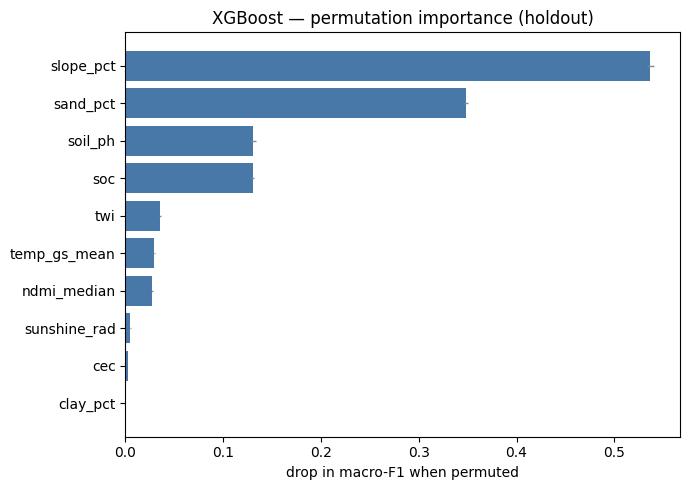

,feature,importance,sd
0,slope_pct,0.53687,0.00329
1,sand_pct,0.34858,0.00222
2,soil_ph,0.13089,0.00246
3,soc,0.13008,0.00120
4,twi,0.03540,0.00079
5,temp_gs_mean,0.02964,0.00067
6,ndmi_median,0.02742,0.00086
7,sunshine_rad,0.00500,0.00030
8,cec,0.00245,0.00017
9,clay_pct,0.00027,0.00022


In [31]:
tick("permutation importance")
idx = np.random.default_rng(SEED).choice(len(X_te), min(PERM_SAMPLE, len(X_te)),
                                         replace=False)
pi = permutation_importance(xgbm, X_te.iloc[idx], y_te[idx], scoring="f1_macro",
                            n_repeats=5, random_state=SEED, n_jobs=1)
imp = (pd.DataFrame({"feature": FEATURES, "importance": pi.importances_mean,
                     "sd": pi.importances_std})
       .sort_values("importance", ascending=False).reset_index(drop=True))
imp.to_csv(p_out("xgb_permutation_importance.csv"), index=False)

t = imp.iloc[::-1]
fig, ax = plt.subplots(figsize=(7, 5))
ax.barh(t["feature"], t["importance"], xerr=t["sd"], color="#4878A8",
        error_kw=dict(ecolor="#888", lw=1))
ax.set_xlabel("drop in macro-F1 when permuted")
ax.set_title("XGBoost — permutation importance (holdout)")
fig.tight_layout(); fig.savefig(p_out("xgb_permutation_importance.png"), dpi=170)
plt.show()
imp.round(5)

## Stage 11 — Accumulated Local Effects

ALE rather than PDP or SHAP, for the reason given in the methodology: the predictors are
correlated, PDP averages over combinations that do not occur, and SHAP attribution is
unstable under collinearity.

The response is the expected suitability level, Σ j·P(class j) on the 0 = N … 3 = S1
scale. XGBoost's probability columns are already in that order.

**Check for `soil_ph` and `temp_gs_mean`:** peaks near 5.85 and 25 °C would mean the model
recovered the Table 3.1 optimum bands from data alone.

[1560.5 min] ALE for all 10 features


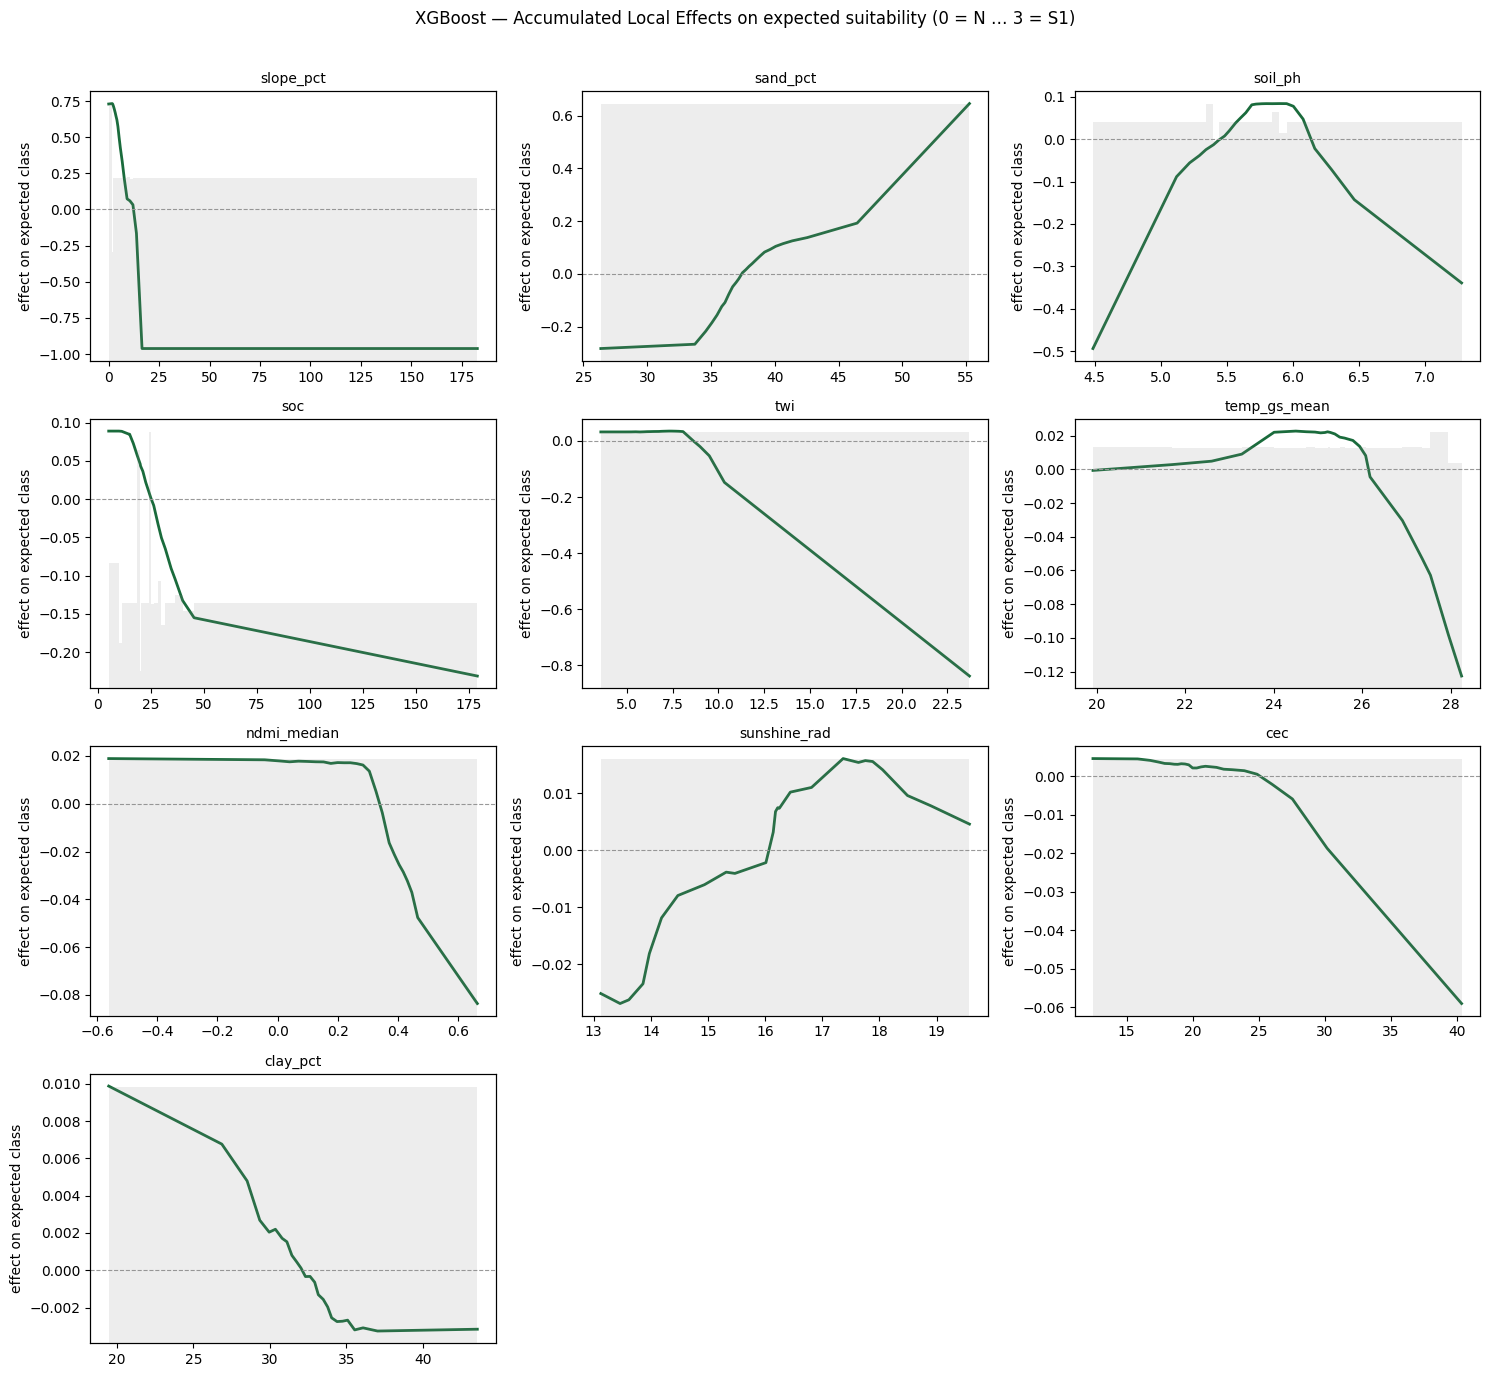

In [32]:
def expected_level(model, X):
    return model.predict_proba(X) @ np.arange(len(ORDER), dtype=float)

def ale_1d(model, X, feature, bins=24, sample=20_000, seed=SEED):
    rs = np.random.default_rng(seed)
    if len(X) > sample:
        X = X.iloc[rs.choice(len(X), sample, replace=False)]
    v = X[feature].to_numpy(dtype=float)
    q = np.unique(np.quantile(v, np.linspace(0, 1, bins + 1)))
    if len(q) < 3:
        return None
    k = np.clip(np.searchsorted(q, v, side="left") - 1, 0, len(q) - 2)
    eff = np.zeros(len(q) - 1); cnt = np.zeros(len(q) - 1)
    for b in range(len(q) - 1):
        m = k == b
        if not m.any():
            continue
        lo, hi = X[m].copy(), X[m].copy()
        lo[feature], hi[feature] = q[b], q[b + 1]
        eff[b] = np.mean(expected_level(model, hi) - expected_level(model, lo))
        cnt[b] = m.sum()
    ale = np.concatenate([[0.0], np.cumsum(eff)])
    centre = np.sum((ale[:-1] + ale[1:]) / 2 * cnt) / max(cnt.sum(), 1)
    return q, ale - centre, cnt

tick("ALE for all 10 features")
fig, axes = plt.subplots(4, 3, figsize=(15, 14))
for ax, f in zip(axes.ravel(), imp["feature"].tolist()):
    out = ale_1d(xgbm, X_te, f)
    if out is None:
        ax.set_visible(False); continue
    q, a, c = out
    ax.plot(q, a, lw=2, color="#1a6b3c")
    ax.axhline(0, color="#999", lw=0.8, ls="--")
    ax2 = ax.twinx(); ax2.bar((q[:-1]+q[1:])/2, c, width=np.diff(q),
                              alpha=0.15, color="#888"); ax2.set_yticks([])
    ax.set_title(f, fontsize=10); ax.set_ylabel("effect on expected class")
for ax in axes.ravel()[len(imp):]:
    ax.set_visible(False)
fig.suptitle("XGBoost — Accumulated Local Effects on expected suitability "
             "(0 = N … 3 = S1)", fontsize=12)
fig.tight_layout(rect=[0, 0, 1, 0.97])
fig.savefig(p_out("xgb_ale_all.png"), dpi=170); plt.show()

## Stage 12 — Three-model comparison

In [33]:
# fill RF figures from rf_outputs/ if present, else edit by hand
LR = dict(cv_macroF1=0.858, holdout_macroF1=0.837, holdout_kappa=0.774,
          holdout_accuracy=0.845, within_one=0.9985)
RF = dict(cv_macroF1=0.9706, holdout_macroF1=0.9774, holdout_kappa=0.9636,
          holdout_accuracy=0.9752, within_one=1.0000)

h = res[res["subset"] == "holdout (all)"].iloc[0]
cmp = pd.DataFrame([
    dict(model="Ordinal LR (baseline)", **LR),
    dict(model="Random forest", **RF),
    dict(model="XGBoost", cv_macroF1=cv.loc["mean", "macroF1"],
         holdout_macroF1=h["macroF1"], holdout_kappa=h["kappa"],
         holdout_accuracy=h["accuracy"], within_one=h["within_one"]),
])
cmp.to_csv(p_out("model_comparison_3way.csv"), index=False)
cmp.round(4)

,model,cv_macroF1,holdout_macroF1,holdout_kappa,holdout_accuracy,within_one
0,Ordinal LR (baseline),0.8580,0.8370,0.7740,0.8450,0.9985
1,Random forest,0.9706,0.9774,0.9636,0.9752,1.0000
2,XGBoost,0.9836,0.9902,0.9850,0.9898,1.0000


### Reading the comparison

- **XGBoost ≈ RF** is the likeliest outcome, and it means the task is saturated: both
  reproduce the rule to within noise, so the remaining error is where the index sits on a
  class boundary. Report it as convergent evidence, not as one model "winning".
- **XGBoost materially above RF** would indicate interactions the forest's independent
  trees could not capture — plausible given the rule's minimum-and-product aggregation.
- **XGBoost below RF** at equal tuning would point at under-training; check whether the
  validation curve in Stage 3 was still falling at the stopping round.
- **The ablation across all three models** remains the result to foreground. If non-rule
  predictors trail in LR, RF *and* XGBoost, the circularity conclusion is model-independent.

Whatever the numbers, the framing does not change: these models reproduce a deterministic
rule from its own inputs. High accuracy is evidence of a faithful surrogate, not of
agronomic discovery.

In [34]:
%run "D:\Projects\capstone\predict_and_map_xgb.py"

XGBoost: 10 features, 1000 rounds (~4000 trees)
features: ['soil_ph', 'slope_pct', 'temp_gs_mean', 'soc', 'cec', 'sand_pct', 'clay_pct', 'ndmi_median', 'twi', 'sunshine_rad']
reading 16 source columns from 94 parts
  10/94  3,540,154 cells (0.5 min)
  20/94  6,519,402 cells (1.0 min)
  30/94  9,938,517 cells (1.5 min)
  50/94  22,082,386 cells (3.2 min)
  60/94  28,322,061 cells (4.4 min)
  70/94  29,931,683 cells (4.8 min)
  80/94  32,579,847 cells (5.2 min)
  90/94  39,037,709 cells (6.1 min)
  94/94  41,592,605 cells (6.5 min)

rendering

comparing against the other models
  cells compared        : 41,592,438
  ordinal LR          :  86.97% correct
  random forest       :  97.95% correct
  XGBoost             :  98.78% correct
  all three agree       :  85.99%

  random forest (rows) vs XGBoost (columns):
          XGB_N    XGB_S3   XGB_S2  XGB_S1
RF_N   22872825     61637       84      77
RF_S3    118812  12330921   125183     301
RF_S2         4    290510  5739476    2784
RF_S1   